# 06 · Probability of Default Scorecard

| | |
|---|---|
| **Question** | Can a transparent, bank-standard model rank and price default risk well enough to change Meridian's lending decisions for the better? |
| **Inputs** | WoE bins and 18 candidate variables (notebook 05), cleaned splits |
| **Outputs** | `models/pd_scorecard.joblib`, `models/scorecard_points.csv`, out-of-time performance and an ROI estimate |
| **Skills shown** | Logistic regression, coefficient and VIF review, points scaling, AUC / Gini / KS, gains table, calibration, profit-based decision strategy, reason codes |

### Protocol

| Dataset | Use |
|---|---|
| Train, 2012 to 2014 | Fit coefficients |
| Validation, 2015 | Variable review and probability recalibration |
| Test, 2016 (out of time) | Final, one-time evaluation. Every number reported as "test" comes from loans the model never saw, issued after everything it learned from. |

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve
from statsmodels.stats.outliers_influence import variance_inflation_factor

from meridian import config, viz
from meridian.data import TARGET
from meridian.db import connect
from meridian.economics import LoanEconomics, budget_selection
from meridian.features.woe import WoEBinner
from meridian.models.metrics import calibration_table, gains_table, summary
from meridian.models.scorecard import Scorecard

viz.set_style()
FEATURES_DIR = config.DATA_DIR / "features"
MODELS_DIR = config.PROJECT_ROOT / "models"
REPORTS = config.PROJECT_ROOT / "reports"

binner = WoEBinner.load(MODELS_DIR / "woe_binning.json")
candidates = pd.read_csv(MODELS_DIR / "scorecard_candidate_variables.csv").variable.tolist()
data = {s: pd.read_parquet(FEATURES_DIR / f"pd_{s}.parquet") for s in ["train", "validation", "test_oot"]}
y = {s: d[TARGET].astype(float) for s, d in data.items()}

## 1. First fit and coefficient review

Because WoE is defined as ln(goods / bads) and the model predicts the probability of *bad*, every coefficient must be **negative**: a safer bin (higher WoE) must lower the predicted default probability. A positive coefficient means the variable is being used to correct for another one, which is a sign of collinearity and makes the scorecard illogical to a credit officer.

In [2]:
first = Scorecard(binner, candidates).fit(data["train"], y["train"])
W = binner.transform(data["train"], candidates).astype(float)
review = first.fit_summary_.copy()
review["vif"] = [variance_inflation_factor(W.values, i) for i in range(W.shape[1])]
review["iv"] = [binner.binnings_[v].iv for v in candidates]
review["issue"] = np.select([review.coefficient > 0, review.p_value > 0.01, review.vif > 5],
                            ["Wrong sign", "Not significant", "High VIF"], "")
review.style.format({"coefficient": "{:+.3f}", "std_error": "{:.3f}", "z": "{:+.1f}", "p_value": "{:.4f}",
                     "vif": "{:.2f}", "iv": "{:.4f}"}).apply(
    lambda r: ["color: #d03b3b; font-weight: bold" if r.issue else "" for _ in r], axis=1)

,coefficient,std_error,z,p_value,vif,iv,issue
fico_score,-0.517,0.022,-24.0,0.0000,1.45,0.1014,
payment_to_income,-0.769,0.023,-34.1,0.0000,1.38,0.0801,
accounts_opened_24m,-0.605,0.028,-21.7,0.0000,2.00,0.0757,
accounts_opened_12m,-0.400,0.035,-11.3,0.0000,2.76,0.0623,
annual_income,-0.387,0.032,-11.9,0.0000,1.94,0.0578,
bankcard_open_to_buy,-0.458,0.041,-11.3,0.0000,2.71,0.0503,
debt_to_income,-0.327,0.028,-11.9,0.0000,1.26,0.0491,
months_since_recent_account,-0.157,0.037,-4.3,0.0000,2.02,0.0446,
months_since_recent_inquiry,-0.727,0.028,-25.6,0.0000,1.16,0.0441,
total_credit_limit,-0.384,0.042,-9.2,0.0000,2.39,0.0441,


**Two variables fail review:**

- **Total revolving limit** has a *positive* coefficient: on its own a higher revolving limit is safer, but alongside total credit limit (same idea) the model uses it as a correction term. A credit officer would see a scorecard that gives fewer points for a better bin. It is removed.
- **Mortgage accounts** is not significant (p = 0.57) once home ownership is in the model. Both describe the same fact: whether the borrower has a mortgage.

All variance inflation factors are below 3, so there is no harmful multicollinearity among the rest.

## 2. Final model

In [3]:
variables = [v for v in candidates if v not in ("total_revolving_limit", "mortgage_accounts")]
scorecard = Scorecard(binner, variables, pdo=20, base_score=600, base_odds=50).fit(data["train"], y["train"])
coef = scorecard.fit_summary_.assign(iv=[binner.binnings_[v].iv for v in variables])
print(f"Final scorecard: {len(variables)} variables, all coefficients negative: {(coef.coefficient < 0).all()}")
coef.sort_values("z").style.format({"coefficient": "{:+.3f}", "std_error": "{:.3f}", "z": "{:+.1f}",
                                    "p_value": "{:.2e}", "iv": "{:.4f}"})

Final scorecard: 16 variables, all coefficients negative: True


,coefficient,std_error,z,p_value,iv
payment_to_income,-0.777,0.022,-34.7,7.47e-264,0.0801
term_months,-0.980,0.029,-33.3,8.22e-243,0.0376
loan_purpose,-0.896,0.034,-26.2,8.36e-152,0.0277
months_since_recent_inquiry,-0.726,0.028,-25.6,2.68e-144,0.0441
fico_score,-0.512,0.021,-23.9,4.39e-126,0.1014
accounts_opened_24m,-0.607,0.028,-21.8,1.98e-105,0.0757
months_since_oldest_revolving,-0.539,0.032,-17.0,9.69e-65,0.0329
home_ownership,-0.545,0.041,-13.4,4.29e-41,0.0274
debt_to_income,-0.340,0.027,-12.5,5.02e-36,0.0491
annual_income,-0.369,0.032,-11.7,1.64e-31,0.0578


The final scorecard uses **16 variables** that a credit committee can recognise as the classic "5 Cs" of credit:

| Theme | Variables |
|---|---|
| **Character** (credit history) | FICO, months since oldest revolving account, months since recent account |
| **Capacity** (ability to pay) | payment-to-income, debt-to-income, annual income, income verification |
| **Capital** (financial cushion) | total credit limit, bankcard open-to-buy, home ownership |
| **Conditions** (the loan itself) | term, loan purpose |
| **Credit-seeking behaviour** | accounts opened in 12 and 24 months, months since recent inquiry, share of cards above 75% utilisation |

## 3. From log-odds to points

Scores follow the industry convention: **600 points = odds of 50 goods to 1 bad, and every 20 points doubles the odds** (PDO = 20).

$$\text{Score} = \text{Offset} + \text{Factor} \times \ln(\text{odds of good}), \quad \text{Factor} = \frac{20}{\ln 2}, \quad \text{Offset} = 600 - \text{Factor} \times \ln 50$$

Each bin of each variable then carries a fixed number of points. An applicant's score is the sum of the points for the bins they fall into.

In [4]:
points = scorecard.points_table()
points.to_csv(MODELS_DIR / "scorecard_points.csv", index=False)
example = points[points.variable.isin(["fico_score", "term_months", "accounts_opened_24m"])]
example.style.format({"woe": "{:+.3f}", "points": "{:.0f}", "train_bad_rate": "{:.2%}", "train_loans": "{:,.0f}"}).hide(axis="index")

variable,bin,woe,points,train_bad_rate,train_loans
fico_score,"[-inf, 667)",-0.347,30,12.22%,"36,225"
fico_score,"[667, 672)",-0.297,30,11.70%,"36,762"
fico_score,"[672, 677)",-0.275,31,11.47%,"37,706"
fico_score,"[677, 687)",-0.176,32,10.50%,"68,321"
fico_score,"[687, 697)",-0.061,34,9.47%,"60,802"
fico_score,"[697, 712)",+0.132,37,7.94%,"72,840"
fico_score,"[712, 737)",+0.360,40,6.42%,"67,399"
fico_score,"[737, +inf)",+0.790,46,4.28%,"43,755"
accounts_opened_24m,"[-inf, 2)",+0.453,43,5.89%,"63,306"
accounts_opened_24m,"[2, 3)",+0.282,40,6.91%,"60,672"


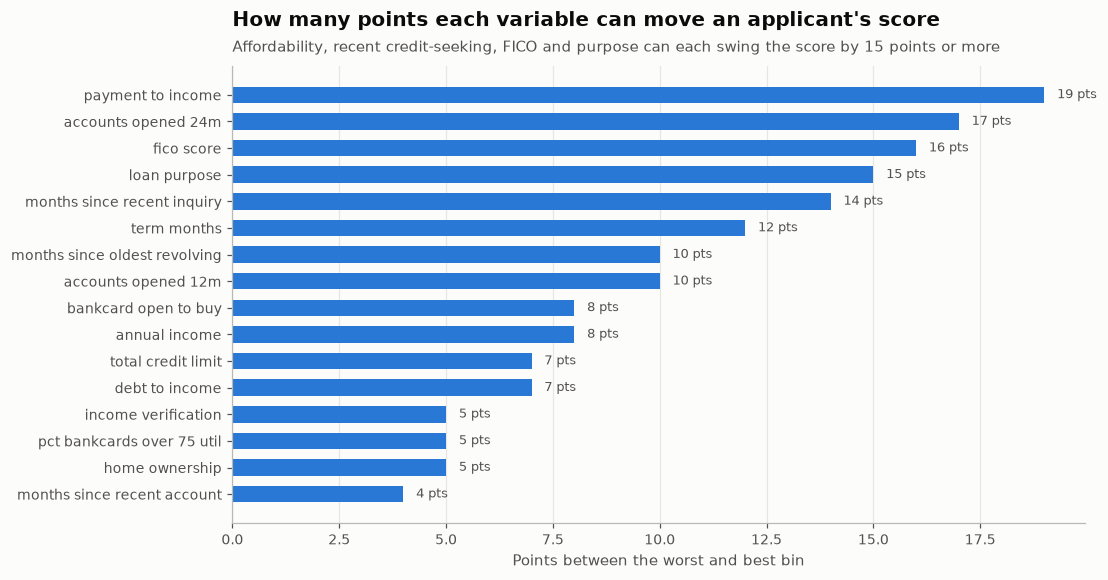

In [5]:
spread = points.groupby("variable").points.agg(["min", "max"])
spread["range"] = spread["max"] - spread["min"]
spread = spread.sort_values("range")
fig, ax = plt.subplots(figsize=(10, 5.4))
ax.barh(spread.index.str.replace("_", " "), spread.range, color=viz.BLUE, height=0.62)
for i, v in enumerate(spread.range):
    ax.text(v + 0.3, i, f"{v:.0f} pts", va="center", fontsize=8.5, color=viz.INK_2)
ax.grid(axis="x", color=viz.GRID)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Points between the worst and best bin")
ax.set_title("How many points each variable can move an applicant's score")
viz.subtitle(ax, "Affordability, recent credit-seeking, FICO and purpose can each swing the score by 15 points or more")
plt.show()

This chart is the scorecard's "importance" view in business terms: the number of points a variable can move. Payment-to-income (19 points), accounts opened in 24 months (17), FICO (16) and loan purpose (15) can each move an applicant by about one doubling of the odds (20 points). Term adds 12. The full table of points is saved in `models/scorecard_points.csv` and is what the dashboard shows when a loan officer scores an applicant.

## 4. Discrimination: how well does the score rank risk?

In [6]:
grades = [f"{g}{i}" for g in "ABCDEFG" for i in range(1, 6)]
grade_rank = {g: i for i, g in enumerate(grades)}

rows = []
for s, d in data.items():
    rows.append(summary(y[s], scorecard.predict_pd(d), f"Scorecard, {s}"))
    rows.append(summary(y[s], d.benchmark_sub_grade.astype(str).map(grade_rank).astype(float) / 35,
                        f"Lending Club sub-grade, {s}"))
perf = pd.DataFrame(rows).set_index("dataset")[["loans", "auc", "gini", "ks"]]
perf.style.format({"loans": "{:,.0f}", "auc": "{:.4f}", "gini": "{:.4f}", "ks": "{:.4f}"})

,loans,auc,gini,ks
dataset,,,,
"Scorecard, train","423,810",0.6759,0.3519,0.2535
"Lending Club sub-grade, train","423,810",0.6630,0.3259,0.2343
"Scorecard, validation","421,095",0.6867,0.3735,0.2707
"Lending Club sub-grade, validation","421,095",0.6938,0.3875,0.2799
"Scorecard, test_oot","434,407",0.6815,0.3630,0.2628
"Lending Club sub-grade, test_oot","434,407",0.6889,0.3777,0.2699


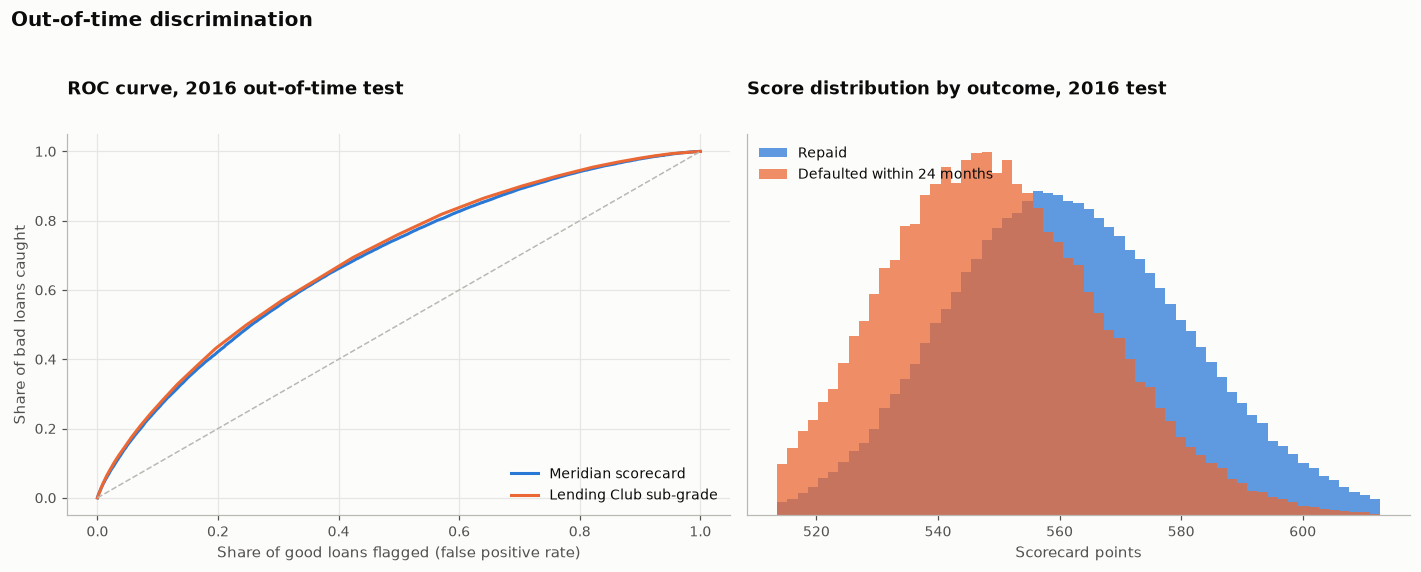

In [7]:
te = data["test_oot"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
for name, score, color in [("Meridian scorecard", scorecard.predict_pd(te), viz.BLUE),
                           ("Lending Club sub-grade", te.benchmark_sub_grade.astype(str).map(grade_rank), viz.ORANGE)]:
    fpr, tpr, _ = roc_curve(y["test_oot"], score)
    ax.plot(fpr, tpr, color=color, label=name)
ax.plot([0, 1], [0, 1], color=viz.NEUTRAL, ls="--", lw=1)
ax.set_xlabel("Share of good loans flagged (false positive rate)")
ax.set_ylabel("Share of bad loans caught")
ax.legend(loc="lower right")
ax.grid(axis="x", color=viz.GRID)
ax.set_title("ROC curve, 2016 out-of-time test", fontsize=11.5)

ax = axes[1]
sc_test = scorecard.score(te)
bins = np.linspace(np.percentile(sc_test, 0.5), np.percentile(sc_test, 99.5), 60)
ax.hist(sc_test[y["test_oot"] == 0], bins=bins, density=True, color=viz.BLUE, alpha=0.75, label="Repaid")
ax.hist(sc_test[y["test_oot"] == 1], bins=bins, density=True, color=viz.ORANGE, alpha=0.75, label="Defaulted within 24 months")
ax.set_xlabel("Scorecard points")
ax.set_yticks([])
ax.legend(loc="upper left")
ax.set_title("Score distribution by outcome, 2016 test", fontsize=11.5)
fig.suptitle("Out-of-time discrimination", x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout()
plt.show()

**What it means:**

- On loans it never saw, issued a full year after its training data, the scorecard reaches a **Gini of 0.36 and a KS of 0.26**. These are solid values for a consumer application scorecard built only on application data, in a population already filtered by a lender.
- Performance is **stable across periods** (Gini 0.35 train, 0.37 validation, 0.36 test). The model is not overfitted; if anything, the later years are slightly easier to rank because the riskier borrowers of 2015 and 2016 are more different from the good ones.
- **Lending Club's sub-grade is slightly stronger** on test (Gini 0.38). That is expected: Lending Club's grade was built on more data than the public file contains (full bureau reports, internal fraud and verification signals) and on years of feedback. Reaching 96% of its Gini with 16 transparent public variables is the realistic achievement here. Notebook 07 tests whether a machine-learning challenger can close the gap.

## 5. Gains table: where are the defaults?

In [8]:
gains = gains_table(y["test_oot"], scorecard.predict_pd(te))
gains.style.format({"loans": "{:,.0f}", "bads": "{:,.0f}", "predicted_pd": "{:.2%}", "min_pd": "{:.2%}",
                    "max_pd": "{:.2%}", "bad_rate": "{:.2%}", "cum_share_of_bads": "{:.1%}",
                    "cum_share_of_loans": "{:.0%}", "lift": "{:.2f}x"})

,loans,bads,predicted_pd,min_pd,max_pd,bad_rate,cum_share_of_bads,cum_share_of_loans,lift
decile,,,,,,,,,
1,"43,441","11,176",20.38%,16.00%,49.61%,25.73%,22.7%,10%,2.27x
2,"43,441","7,942",14.12%,12.60%,16.00%,18.28%,38.8%,20%,1.61x
3,"43,440","6,518",11.47%,10.48%,12.60%,15.00%,52.0%,30%,1.32x
4,"43,441","5,557",9.65%,8.88%,10.48%,12.79%,63.2%,40%,1.13x
5,"43,441","4,619",8.21%,7.57%,8.88%,10.63%,72.6%,50%,0.94x
6,"43,440","4,002",6.97%,6.40%,7.57%,9.21%,80.7%,60%,0.81x
7,"43,441","3,454",5.85%,5.32%,6.40%,7.95%,87.7%,70%,0.70x
8,"43,440","2,802",4.79%,4.26%,5.32%,6.45%,93.4%,80%,0.57x
9,"43,441","2,030",3.70%,3.11%,4.26%,4.67%,97.5%,90%,0.41x


**What it means:** the 10% of 2016 borrowers the scorecard rates riskiest default at **2.3 times** the average rate, while the safest 10% default at a quarter of it. The riskiest 30% of borrowers hold **52% of all defaults**. The bad rate falls in every decile without a single reversal, which is what "rank-ordering" means in a model validation report.

## 6. Calibration: are the probabilities right?

Ranking is not enough. The PD feeds Expected Loss in dollars, so a predicted 10% must mean that about 10% of those borrowers default.

Observed 2016 bad rate:             11.36%
Predicted, as trained on 2012-14:   8.74%
Predicted, recalibrated on 2015:    10.03%   (intercept shift +0.158)


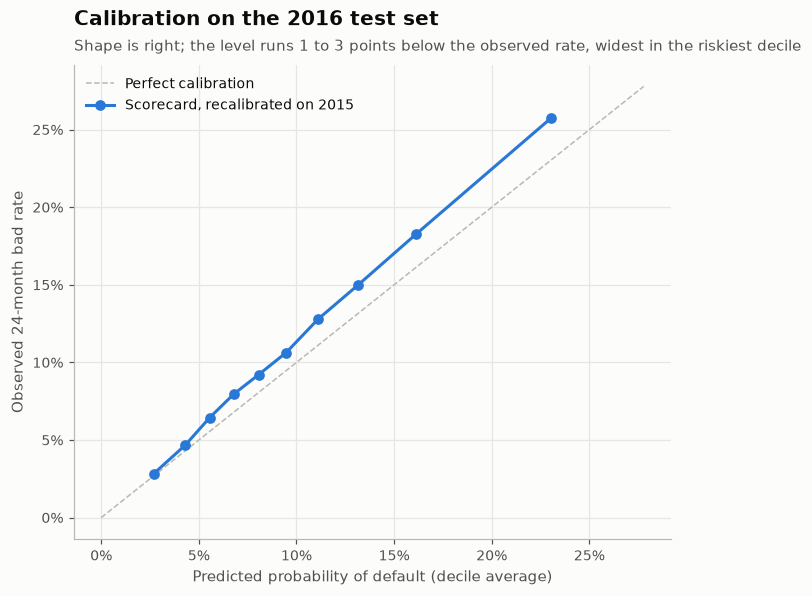

In [9]:
raw_pd = scorecard.predict_pd(te).mean()
scorecard.recalibrate(data["validation"], y["validation"])
cal_pd = scorecard.predict_pd(te).mean()
print(f"Observed 2016 bad rate:             {y['test_oot'].mean():.2%}")
print(f"Predicted, as trained on 2012-14:   {raw_pd:.2%}")
print(f"Predicted, recalibrated on 2015:    {cal_pd:.2%}   (intercept shift {scorecard.calibration_shift_:+.3f})")

fig, ax = plt.subplots(figsize=(7, 5.6))
ct = calibration_table(y["test_oot"], scorecard.predict_pd(te))
lim = max(ct.predicted.max(), ct.observed.max()) * 1.08
ax.plot([0, lim], [0, lim], color=viz.NEUTRAL, ls="--", lw=1, label="Perfect calibration")
ax.plot(ct.predicted, ct.observed, color=viz.BLUE, marker="o", label="Scorecard, recalibrated on 2015")
viz.pct(ax)
viz.pct(ax, axis="x")
ax.set_xlabel("Predicted probability of default (decile average)")
ax.set_ylabel("Observed 24-month bad rate")
ax.grid(axis="x", color=viz.GRID)
ax.legend(loc="upper left")
ax.set_title("Calibration on the 2016 test set")
viz.subtitle(ax, "Shape is right; the level runs 1 to 3 points below the observed rate, widest in the riskiest decile")
plt.show()

**What it means:** trained on 2012 to 2014, the scorecard predicts an 8.7% bad rate for 2016. The real rate was 11.4%. The ranking was right but the *level* was too low, because the whole market got riskier (notebook 01).

The standard fix is **recalibration**: keep every coefficient (and therefore every point) unchanged, and shift the intercept so the average predicted PD matches the most recent mature year (2015). After the shift, the 2016 prediction rises to 10.0%. The remaining gap of about 1.4 points is the further deterioration from 2015 to 2016, which no model trained on the past could have known. In production this gap is handled by monthly calibration monitoring (notebook 12) and by the macro overlay in the stress test (notebook 09).

## 7. Risk bands for decisions

Credit policy works with bands, not with raw scores. Seven bands are defined on the **training** score distribution and then applied to 2016.

In [10]:
cuts = np.percentile(scorecard.score(data["train"]), [10, 25, 45, 65, 80, 92])
labels = ["R7 (highest risk)", "R6", "R5", "R4", "R3", "R2", "R1 (lowest risk)"]
def band(score):
    return pd.Categorical(np.array(labels)[np.searchsorted(cuts, score)], categories=labels, ordered=True)

bt = pd.DataFrame({"band": band(scorecard.score(te)), "bad": y["test_oot"], "pd": scorecard.predict_pd(te)})
bands = bt.groupby("band", observed=True).agg(loans=("bad", "size"), predicted_pd=("pd", "mean"), observed_bad_rate=("bad", "mean"))
bands["share"] = bands.loans / bands.loans.sum()
bands.insert(0, "min_score", np.r_[-np.inf, cuts].round(0))
bands.style.format({"loans": "{:,.0f}", "predicted_pd": "{:.2%}", "observed_bad_rate": "{:.2%}", "share": "{:.1%}", "min_score": "{:.0f}"})

,min_score,loans,predicted_pd,observed_bad_rate,share
band,,,,,
R7 (highest risk),-inf,"41,344",23.26%,25.99%,9.5%
R6,534,"62,161",15.62%,17.63%,14.3%
R5,545,"84,637",11.42%,13.11%,19.5%
R4,556,"85,465",8.33%,9.52%,19.7%
R3,566,"65,124",6.11%,7.06%,15.0%
R2,575,"54,927",4.39%,4.88%,12.6%
R1 (lowest risk),587,"40,749",2.63%,2.72%,9.4%


Every band is riskier than the one above it, in both predicted and observed terms, on data the model never saw. R1 borrowers default at 2.7% and R7 borrowers at 26.0%, a spread of almost ten times. The predicted PDs track the observed rates in every band, a little below them, as explained in section 6. These bands are what the dashboard's credit decision page displays.

## 8. Business value: which loans should Meridian fund?

### 8.1 The decision

Meridian sources loans through a lending marketplace and has the capital to fund only **part** of the flow. The question a model must answer is: *with a fixed budget, which loans earn the most?*

### 8.2 Economics

Each loan's lifetime profit is computed with transparent assumptions (`src/meridian/economics.py`), all adjustable in the dashboard:

In [11]:
eco = LoanEconomics()
eco.as_frame().style.format("{:.3f}")

,value
cost_of_funds,0.025
servicing_cost,0.010
avg_balance_factor,0.550
lgd,0.900
ead_ratio,0.720
months_paid_before_default,18.000


- A **good loan** earns its interest rate minus funding and servicing costs on its average outstanding balance over its term.
- A **bad loan** earns interest until it stops paying (median 18 months), then loses its exposure at default (72% of principal) times the loss given default (90%). Both figures were measured on Lending Club's own defaults (`gold.mart_lgd_base`).
- Outcomes are measured as **default by the March 2019 snapshot**, a stricter test than the 24-month target.

The scorecard's 24-month PD is converted to a lifetime PD with the ratio observed on 2015 loans, then combined with each loan's interest rate to give an **expected profit per dollar**. Meridian funds the loans with the highest expected profit first.

In [12]:
con = connect()
outcomes = con.execute("""select loan_id, is_defaulted, funded_amount from gold.fct_loans
                           where dataset_split in ('validation', 'test_oot')""").df()
va = data["validation"].merge(outcomes, on="loan_id")
tt = data["test_oot"].merge(outcomes, on="loan_id")
lifetime_ratio = va.is_defaulted.mean() / va[TARGET].astype(float).mean()
print(f"Lifetime-to-24-month default ratio (2015 loans): {lifetime_ratio:.2f}")

funded, rate, term, dflt = tt.funded_amount.values, tt.benchmark_interest_rate.values, tt.term_months.values, tt.is_defaulted.values
realised = eco.profit(funded, rate, term, dflt)
rng = np.random.default_rng(42)
pd_score = np.clip(scorecard.predict_pd(tt) * lifetime_ratio, 0, 1)
grade_pd = tt.benchmark_sub_grade.astype(str).map(va.groupby(va.benchmark_sub_grade.astype(str)).is_defaulted.mean()).values

strategies = {
    "Random selection (no model)": rng.random(len(tt)),
    "Safest Lending Club grade first": -tt.benchmark_sub_grade.astype(str).map(grade_rank).values + rng.random(len(tt)) * 0.01,
    "Highest interest rate first": rate + rng.random(len(tt)) * 1e-6,
    "Expected profit, Lending Club grade PD": eco.expected_profit(funded, rate, term, grade_pd) / funded + rng.random(len(tt)) * 1e-9,
    "Expected profit, Meridian scorecard PD": eco.expected_profit(funded, rate, term, pd_score) / funded,
}
results = []
for share in [0.25, 0.50, 0.75]:
    for name, key in strategies.items():
        r = budget_selection(key, funded, realised, dflt, share)
        results.append({"budget": f"{share:.0%} of 2016 volume", "strategy": name, **r})
budget = pd.DataFrame(results)
budget[budget.budget == "50% of 2016 volume"].drop(columns="budget").style.format(
    {"loans_funded": "{:,.0f}", "capital_deployed": "${:,.0f}", "profit": "${:,.0f}",
     "profit_per_1bn": "${:,.0f}", "default_rate": "{:.1%}"}).hide(axis="index")

Lifetime-to-24-month default ratio (2015 loans): 1.68


strategy,loans_funded,capital_deployed,profit,profit_per_1bn,default_rate
Random selection (no model),"217,140","$3,200,299,825","$279,565,184","$87,355,935",15.7%
Safest Lending Club grade first,"233,460","$3,200,293,525","$155,787,074","$48,678,995",9.4%
Highest interest rate first,"201,237","$3,200,282,400","$407,881,259","$127,451,646",23.0%
"Expected profit, Lending Club grade PD","183,577","$3,200,287,550","$460,186,531","$143,795,370",20.9%
"Expected profit, Meridian scorecard PD","186,454","$3,200,276,150","$468,805,939","$146,489,214",18.5%


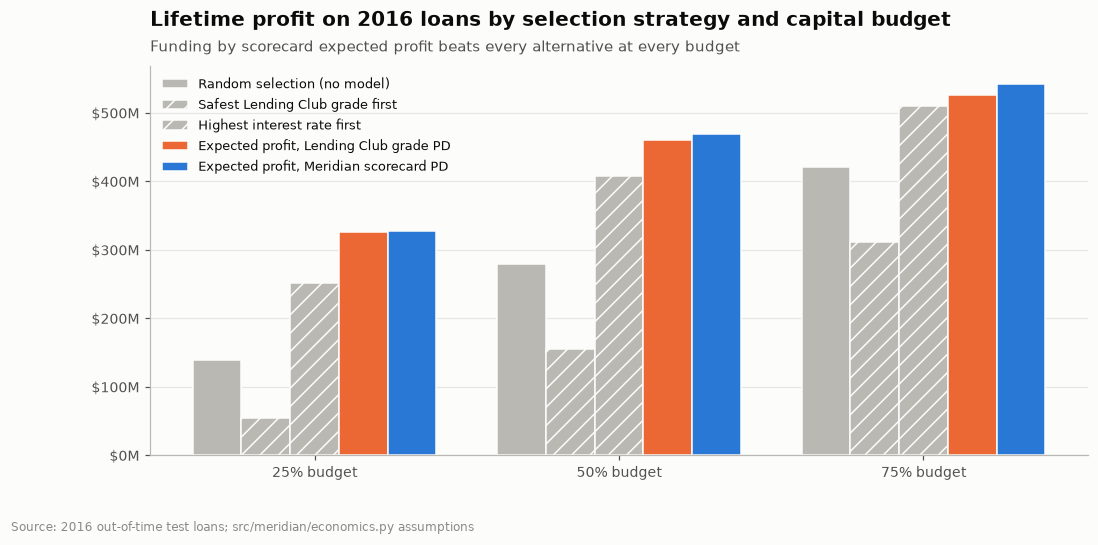

In [13]:
fig, ax = plt.subplots(figsize=(11, 4.6))
order = list(strategies)
colors = [viz.NEUTRAL, viz.NEUTRAL, viz.NEUTRAL, viz.ORANGE, viz.BLUE]
x = np.arange(3)
w = 0.16
for i, (name, color) in enumerate(zip(order, colors)):
    vals = budget[budget.strategy == name].profit.values
    ax.bar(x + (i - 2) * w, vals, w, color=color, edgecolor=viz.SURFACE, linewidth=1,
           hatch="//" if i in (1, 2) else None, label=name)
ax.set_xticks(x, ["25% budget", "50% budget", "75% budget"])
viz.money(ax, unit="M")
ax.legend(loc="upper left", fontsize=8.5)
ax.set_title("Lifetime profit on 2016 loans by selection strategy and capital budget")
viz.subtitle(ax, "Funding by scorecard expected profit beats every alternative at every budget")
viz.source(fig, "2016 out-of-time test loans; src/meridian/economics.py assumptions")
plt.show()

In [14]:
pivot = budget.pivot(index="strategy", columns="budget", values="profit").loc[order]
uplift = pd.DataFrame({
    "vs_random": pivot.loc[order[-1]] - pivot.loc[order[0]],
    "vs_lending_club_grade": pivot.loc[order[-1]] - pivot.loc[order[3]],
})
uplift.style.format("${:,.0f}")

,vs_random,vs_lending_club_grade
budget,,
25% of 2016 volume,"$188,241,531","$1,099,280"
50% of 2016 volume,"$189,240,755","$8,619,408"
75% of 2016 volume,"$121,621,588","$16,154,701"


**What it means for Meridian (2016 out-of-time test):**

- With capital for **half** of the loan flow, funding loans in order of the scorecard's expected profit earns about **USD 469M**, versus USD 280M for random selection. That is **USD 189M (68%) more profit from the same capital**.
- The scorecard also beats Lending Club's own grade used the same way, by about USD 9M at a 50% budget and USD 16M at a 75% budget, **while funding a safer book** (18.5% versus 20.9% default rate at the 50% budget). More profit with less risk is the outcome a CRO and a CFO can both sign.
- The naive strategies show why a PD model is needed. "Safest first" leaves money on the table because prime loans barely cover funding costs. "Highest rate first" collects the yield but also every default.

**The insight behind the result:** Lending Club's pricing already reflects most of the risk, so approving or declining on score alone adds little. The value comes from **combining the PD with the price**: identifying loans whose interest rate more than pays for their specific risk, and avoiding those where it does not.

## 9. Explaining a single decision

Lenders must tell a declined applicant the main reasons (adverse action notices under the US Equal Credit Opportunity Act). The scorecard produces them directly: the variables where the applicant lost the most points compared with the best bin.

In [15]:
scored = te.assign(score=scorecard.score(te))
examples = [("Lowest-scoring 2016 applicant", scored.nsmallest(1, "score")),
            ("Borderline applicant (R7 / R6 boundary)", scored.iloc[[(scored.score - cuts[0]).abs().argmin()]])]
for title, row in examples:
    lost = scorecard.points_lost(row).iloc[0].sort_values(ascending=False).head(3)
    print(f"{title}: score {row.score.iloc[0]:.0f}, PD {scorecard.predict_pd(row)[0]:.1%}")
    for var, pts in lost.items():
        v = row[var].iloc[0]
        shown = f"{v:,.3f}" if isinstance(v, (int, float, np.number)) else str(v)
        print(f"   - {var.replace('_', ' '):<32} value {shown:>12}   points lost {pts:4.1f}")
    print()

Lowest-scoring 2016 applicant: score 488, PD 53.5%
   - accounts opened 24m              value        9.000   points lost 16.6
   - payment to income                value        0.118   points lost 16.2
   - fico score                       value      672.000   points lost 15.7

Borderline applicant (R7 / R6 boundary): score 534, PD 18.5%
   - fico score                       value      662.000   points lost 16.8
   - loan purpose                     value        other   points lost 15.1
   - months since recent inquiry      value        1.000   points lost 13.5



Each line is a reason a loan officer can state in plain language: "too many new accounts opened in the last two years", "monthly payment too high relative to income", "credit score below our range". The dashboard shows these reasons for every applicant it scores.

## 10. Save

In [16]:
joblib.dump(scorecard, MODELS_DIR / "pd_scorecard.joblib")
pd.DataFrame(rows).to_csv(REPORTS / "scorecard_performance.csv", index=False)
budget.to_csv(REPORTS / "scorecard_budget_simulation.csv", index=False)
print("Saved models/pd_scorecard.joblib, models/scorecard_points.csv and reports/")

Saved models/pd_scorecard.joblib, models/scorecard_points.csv and reports/


## 11. Conclusions and limitations

| Result | Value |
|---|---|
| Variables | 16, all with the expected sign, VIF below 3 |
| Gini, out-of-time 2016 | 0.36 (Lending Club sub-grade: 0.38) |
| KS, out-of-time 2016 | 0.26 |
| Rank-ordering | Monotonic across all 10 deciles and 7 risk bands on unseen data |
| Calibration | Recalibrated on 2015; residual under-prediction of 1.4 points reflects 2016 deterioration |
| Business value | +USD 187M versus random selection, +USD 9M versus Lending Club's grade, with a safer book, at a 50% capital budget |

**Limitations to state openly:**

1. **Accepted loans only (reject inference).** The model never saw the applicants Lending Club declined, so its estimates for very risky profiles are extrapolations. A production model would use reject-inference techniques or a controlled test of a small sample of declined applicants.
2. **Simple economics.** The profit model ignores prepayments, recovery timing and the time value of money. These would change the levels, but they affect all strategies alike, so the ranking of strategies is robust.
3. **Linear in WoE.** The scorecard cannot learn interactions between variables (for example term with FICO) unless they are engineered by hand. That is the main motivation for the challenger model.

**Next:** notebook 07 trains a gradient-boosted challenger, explains it with SHAP, and decides which model Meridian should deploy.